# Setup

In [ ]:
import pairadigm as pdm
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.optim import AdamW
from torch.amp import autocast, GradScaler
from typing import List, Tuple, Optional, Union, Dict
import numpy as np
from tqdm import tqdm
import json
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import pearsonr
from pairadigm import Pairadigm
import copy
import random
import polars as pl

import sys
from datetime import datetime
import os

/nfshomes/mlchrzan/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Setup logging to file for tmux sessions

# Create logs directory if it doesn't exist
# os.makedirs("../Model Training/training_logs", exist_ok=True)

# # Create log file with timestamp
# log_file = f"../Model Training/training_logs/training_log_emobank_reward_{datetime.now().strftime('%Y%m%d_%H%M%S')}.txt"

# # Redirect stdout and stderr to log file while keeping console output
# class Tee:
#     def __init__(self, *files):
#         self.files = files
#     def write(self, obj):
#         for f in self.files:
#             f.write(obj)
#             f.flush()
#     def flush(self):
#         for f in self.files:
#             f.flush()

# log_file_handle = open(log_file, 'w')
# sys.stdout = Tee(sys.stdout, log_file_handle)
# sys.stderr = Tee(sys.stderr, log_file_handle)

# print(f"Logging to: {log_file}")
# print(f"Training started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

In [3]:
# Set random seeds for reproducibility
def set_seeds(seed: int = 42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Detect best device available
def get_best_device(cuda_index: int = 0, verbose: bool = True):
    """Detect best device: CUDA (with index) > MPS > CPU"""
    if torch.cuda.is_available():
        if cuda_index < torch.cuda.device_count():
            device = torch.device(f"cuda:{cuda_index}")
            device_name = f"cuda:{cuda_index}"
            if verbose:
                try:
                    print(f"Using NVIDIA GPU {cuda_index}: {torch.cuda.get_device_name(cuda_index)}")
                except Exception:
                    print(f"Using NVIDIA GPU {cuda_index}")
        else:
            raise ValueError(f"CUDA device {cuda_index} not available. Available devices: 0 to {torch.cuda.device_count()-1}")

    elif torch.backends.mps.is_available():
        device = torch.device("mps")
        device_name = "mps"
        if verbose:
            print("Using Apple Silicon GPU via MPS")
    else:
        device = torch.device("cpu")
        device_name = "cpu"
        if verbose:
            print("No GPU found, using CPU")
    return device, device_name

# Example usage
set_seeds(42)
device, device_name = get_best_device(cuda_index=0, verbose=True)

Using NVIDIA GPU 0: NVIDIA RTX 4000 Ada Generation


# Prep Data

In [8]:
# Load with Polars (faster)
emobank = pl.read_csv("../Data/emobank.csv").to_pandas()
V = pl.read_csv("../Data/pairwise_probs_V.csv").to_pandas() # NOTE: we are not using it for training the reward model, will use the original EmoBank data instead
A = pl.read_csv("../Data/pairwise_probs_A.csv").to_pandas()
D = pl.read_csv("../Data/pairwise_probs_D.csv").to_pandas()

# Drop the Unnamed column if it exists
for df in [emobank, A, D]:
    if 'Unnamed: 0' in df.columns:
        df.drop(columns=['Unnamed: 0'], inplace=True)

!!! NOTE: DECIDED to NOT use the same pairs as in EmoPair and just take a random set of pairs generated from EmoBank training split to have more data for training the reward model. 

In [ ]:
# # Filter V, A, and D to only include rows where the pair are the same as those used in EmoPair

# # Get the EmoPair pairs
# emopair_pairs = pl.read_csv("../Results/emopair_aro_untied_pairwise_annotations.csv").to_pandas()
# emopair_pairs.rename(columns={'item1': 'Item_A', 'item2': 'Item_B'}, inplace=True)

# # Create a normalized pair set for matching (order-independent) - vectorized
# emopair_pairs['pair_key'] = emopair_pairs.apply(
#     lambda row: tuple(sorted([row['Item_A'], row['Item_B']])), 
#     axis=1
# )
# emopair_pair_keys = set(emopair_pairs['pair_key'])

# def filter_by_pair_key_fast(df, pair_keys):
#     """Filter dataframe by matching pairs (order-independent) - vectorized."""
#     df_copy = df.copy()
#     # Vectorized: create pair keys without apply()
#     pair_keys_df = np.sort(df_copy[['Item_A', 'Item_B']].values, axis=1)
#     pair_keys_df = [tuple(row) for row in pair_keys_df]
    
#     mask = np.array([key in pair_keys for key in pair_keys_df])
#     return df_copy[mask]

# # Filter - now much faster
# V_filtered = filter_by_pair_key_fast(V, emopair_pair_keys)
# A_filtered = filter_by_pair_key_fast(A, emopair_pair_keys)
# D_filtered = filter_by_pair_key_fast(D, emopair_pair_keys)

# # Verify the number of rows match
# assert len(V_filtered) == len(A_filtered) == len(D_filtered), "Filtered V, A, and D do not have the same number of rows after merging."
# print(f"Number of pairwise comparisons after filtering: {len(V_filtered)}")

In [ ]:
# # Merge V, A, and D into a single DataFrame

# cols_to_keep = ['Item_A', 'Item_B', 'Probability_A_greater_B', 'A_better_indicator']
# V_filtered = V_filtered[cols_to_keep]
# A_filtered = A_filtered[cols_to_keep]
# D_filtered = D_filtered[cols_to_keep]

# pairwise_data = V_filtered.merge(A_filtered, on=['Item_A', 'Item_B'], suffixes=('_V', '_A'))
# pairwise_data = pairwise_data.merge(D_filtered, on=['Item_A', 'Item_B'])

# # Add _D suffix for D columns
# pairwise_data.rename(columns={'Probability_A_greater_B': 'Probability_A_greater_B_D',
#                                'A_better_indicator': 'A_better_indicator_D'}, inplace=True)

# pairwise_data

## Generate Pairs for Train - Dev - Test Set

In [6]:
def join_texts(pairwise_probs, emobank):
    """Join the texts from emobank to the pairwise probabilities dataframe."""

    texts = emobank[['id', 'text']]

    merge = pairwise_probs.merge(
        texts,
        left_on="Item_A",
        right_on="id",
        how="left"
    ).rename(columns={"text": "Text_A"}).drop(columns=["id"]).merge(
        texts,
        left_on="Item_B",
        right_on="id",
        how="left"
    ).rename(columns={"text": "Text_B"}).drop(columns=["id"])

    return merge

In [ ]:
# DECIDED to NOT use the same pairs as in EmoPair and just take a random set of pairs generated from EmoBank training split to have more data for training the reward model. 

# # Get IDs for each split
# train_ids = emobank[emobank['split'] == "train"]['id'].copy().to_list()
# # dev_ids = emobank[emobank['split'] == "dev"]['id'].copy().to_list()

# # Filter pairwise_data for train (both items in train)
# train_set_pairs = pairwise_data[
#     (pairwise_data['Item_A'].isin(train_ids)) &
#     (pairwise_data['Item_B'].isin(train_ids))
# ].reset_index(drop=True)

# # Too few dev pairs, so generating them from EmoBank like I did with the test set below
# # eval_set_pairs = pairwise_data[
# #     (pairwise_data['Item_A'].isin(dev_ids)) &
# #     (pairwise_data['Item_B'].isin(dev_ids))
# # ].reset_index(drop=True)

# print(f"Train pairs: {len(train_set_pairs)}")
# # print(f"Eval pairs: {len(eval_set_pairs)}")

# train_set_pairs = join_texts(train_set_pairs, emobank)
# train_set_pairs

In [ ]:
# # Verify that no pair in eval_set_pairs has its reverse also present
# pairs = set(zip(eval_set_pairs['Item_A'], eval_set_pairs['Item_B']))
# reversed_pairs = {(b, a) for (a, b) in pairs}
# conflicts = pairs & reversed_pairs

# if not conflicts:
#     print("PASS: No reversed Item_A/Item_B pairs found in eval_set_pairs.")
# else:
#     # Report unique unordered conflicts
#     uniq_conflicts = {tuple(sorted(p)) for p in conflicts}
#     print(f"FAIL: Found {len(uniq_conflicts)} reversed pair(s) (showing up to 10):")
#     for i, p in enumerate(list(uniq_conflicts)[:10], 1):
#         print(f"{i}. {p[0]}  <->  {p[1]}")
#     raise AssertionError(f"Reversed pairs exist in eval_set_pairs: {len(uniq_conflicts)} found.")

In [ ]:
# # Augmentation of eval pairs, still too noisy, won't train
# def augment_pairs_with_flips(pairs_df):
#     """
#     Double the dataset by flipping each pair and inverting probabilities.
    
#     For pair (A, B) with prob_V = 0.7, create pair (B, A) with prob_V = 0.3
#     """
#     flipped = pairs_df.copy()
    
#     # Swap Item_A and Item_B
#     flipped['Item_A'], flipped['Item_B'] = pairs_df['Item_B'].copy(), pairs_df['Item_A'].copy()
    
#     # Swap texts
#     if 'Text_A' in flipped.columns and 'Text_B' in flipped.columns:
#         flipped['Text_A'], flipped['Text_B'] = pairs_df['Text_B'].copy(), pairs_df['Text_A'].copy()
    
#     # Invert probabilities: if P(A > B) = 0.7, then P(B > A) = 0.3
#     for dim in ['V', 'A', 'D']:
#         prob_col = f'Probability_A_greater_B_{dim}'
#         flipped[prob_col] = 1.0 - pairs_df[prob_col]
        
#         # Also flip the indicator
#         indicator_col = f'A_better_indicator_{dim}'
#         if indicator_col in flipped.columns:
#             flipped[indicator_col] = 1 - pairs_df[indicator_col]
    
#     # Combine original and flipped
#     augmented = pd.concat([pairs_df, flipped], ignore_index=True)
    
#     return augmented

# # Apply to eval set
# eval_set_pairs_augmented = augment_pairs_with_flips(eval_set_pairs)
# print(f"Original eval pairs: {len(eval_set_pairs)}")
# print(f"Augmented eval pairs: {len(eval_set_pairs_augmented)}")
# eval_set_pairs = eval_set_pairs_augmented.copy()

In [ ]:
# OLD - error with the pairings because they weren't respecting ordering 
# def prepare_pairs(split: str, V, A, D, emobank, seed_num: int = 42):
#     """
#     Prepare pairs from emopair/emobank dataset with V/A/D probabilities.
    
#     Args:
#         split: 'dev' or 'test' split from emopair
#         V, A, D: DataFrames with pairwise probabilities
#         emobank: DataFrame with text data
#         seed_num: random seed for reproducibility
        
#     Returns:
#         DataFrame with pairs and probabilities for all three dimensions
#     """
#     set_seeds(seed_num)
#     num_pairs_per_item = 10
#     if split == 'train':
#         num_pairs_per_item = 12

#     # Get IDs 
#     emobank_subset = emobank[emobank['split'] == split].copy()
    
#     subset_ids = emobank_subset['id'].to_list()
#     subset_pairs = pdm.pair_items(subset_ids, 
#                                   num_pairs_per_item=num_pairs_per_item,
#                                   random_seed=seed_num)
    
#     # Rename for consistency
#     subset_pairs.rename(columns={'item1': 'Item_A', 'item2': 'Item_B'}, inplace=True)
#     subset_pairs = join_texts(subset_pairs, emobank)
    
#     # Create pair keys for matching
#     subset_pairs['pair_key'] = [
#         tuple(sorted(pair)) 
#         for pair in zip(subset_pairs['Item_A'], subset_pairs['Item_B'])
#     ]
#     subset_pair_keys = set(subset_pairs['pair_key'])
    
#     # Merge V, A, D probabilities
#     for df, dim_name in zip([V, A, D], ['V', 'A', 'D']):
#         # Create pair keys
#         df['pair_key'] = [
#             tuple(sorted(pair)) 
#             for pair in zip(df['Item_A'], df['Item_B'])
#         ]
        
#         # Filter to only subset pairs
#         df_subset = df[df['pair_key'].isin(subset_pair_keys)].copy()
        
#         # Clean up and rename columns
#         df_subset = df_subset[['pair_key', 'Probability_A_greater_B', 'A_better_indicator']].copy()
#         df_subset.rename(columns={
#             'Probability_A_greater_B': f'Probability_A_greater_B_{dim_name}',
#             'A_better_indicator': f'A_better_indicator_{dim_name}'
#         }, inplace=True)
        
#         # Merge on pair_key
#         subset_pairs = subset_pairs.merge(df_subset, on='pair_key', how='left')
    
#     # Drop pair_key column
#     subset_pairs.drop(columns=['pair_key'], inplace=True)
    
#     return subset_pairs

In [9]:
def prepare_pairs(split: str, V, A, D, emobank, seed_num: int = 42):
    """
    Prepare pairs from emopair/emobank dataset with V/A/D probabilities.
    """
    set_seeds(seed_num)
    num_pairs_per_item = 10
    if split == 'train':
        num_pairs_per_item = 12

    # Get IDs 
    emobank_subset = emobank[emobank['split'] == split].copy()
    
    subset_ids = emobank_subset['id'].to_list()
    subset_pairs = pdm.pair_items(subset_ids, 
                                  num_pairs_per_item=num_pairs_per_item,
                                  random_seed=seed_num)
    
    # Rename for consistency
    subset_pairs.rename(columns={'item1': 'Item_A', 'item2': 'Item_B'}, inplace=True)
    subset_pairs = join_texts(subset_pairs, emobank)
    
    # Merge V, A, D probabilities with order-aware matching
    for df, dim_name in zip([V, A, D], ['V', 'A', 'D']):
        # Try direct match (same order: subset A=df A, subset B=df B)
        direct = subset_pairs.merge(
            df[['Item_A', 'Item_B', 'Probability_A_greater_B', 'A_better_indicator']],
            on=['Item_A', 'Item_B'],
            how='left'
        )
        
        # Try reverse match (flipped order: subset A=df B, subset B=df A)
        df_flipped = df[['Item_A', 'Item_B', 'Probability_A_greater_B', 'A_better_indicator']].copy()
        df_flipped.rename(columns={'Item_A': 'Item_B', 'Item_B': 'Item_A'}, inplace=True)
        # Flip the probability and indicator for reversed pairs
        df_flipped['Probability_A_greater_B'] = 1.0 - df_flipped['Probability_A_greater_B']
        df_flipped['A_better_indicator'] = 1 - df_flipped['A_better_indicator']
        
        reverse = subset_pairs[['Item_A', 'Item_B']].merge(
            df_flipped,
            on=['Item_A', 'Item_B'],
            how='left'
        )
        
        # Combine: use direct match where available, fall back to reverse
        prob_col = f'Probability_A_greater_B_{dim_name}'
        ind_col = f'A_better_indicator_{dim_name}'
        
        subset_pairs[prob_col] = direct['Probability_A_greater_B'].fillna(
            reverse['Probability_A_greater_B']
        )
        subset_pairs[ind_col] = direct['A_better_indicator'].fillna(
            reverse['A_better_indicator']
        )
    
    return subset_pairs

In [17]:
train_set_pairs = prepare_pairs('train', V, A, D, emobank, seed_num=42)
train_set_pairs

,Item_A,Item_B,Text_A,Text_B,Probability_A_greater_B_V,A_better_indicator_V,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,SemEval_827,detroit_16815_16847,Looking beyond the iPhone,Freaking hillarious and so true.,0.10,0.0,0.20,0.0,0.3,0.0
1,Uprooted_Farming-on-Sand_2195_2306,Uprooted_Farming-on-Sand_2307_2439,This makes it an excellent and bountiful sourc...,"But haying had to happen regularly, says David...",0.92,1.0,0.50,0.0,0.7,1.0
2,115CVL036_422_638,Nathans_Bylichka_34163_34176,It's clear that if we don't increase our base ...,Still woozy?”,0.50,1.0,0.50,1.0,0.6,1.0
3,detroit_1917_2009,detroit_2010_2061,We had plenty to choose from: there were more ...,"We picked two neighborhoods to cruise, and dov...",0.72,1.0,0.58,1.0,0.4,0.0
4,SemEval_907,easy_money_8786_8790,That'll cost ya,Yes.,0.50,1.0,0.60,1.0,0.7,1.0
...,...,...,...,...,...,...,...,...,...,...
55505,IFAW1_4131_4221,united1_132_307,"Gifts of $100, $25, and $15 all are important ...","Great destinations, your choice of itineraries...",0.50,0.0,0.70,1.0,0.7,1.0
55506,Black_and_white_20022_20276,Black_and_white_20277_20326,Now we have entered an era where we are seeing...,Thus is the ebb and flow of life.,0.50,0.0,0.60,1.0,0.7,1.0
55507,602CZL285_260_452,SemEval_531,The SCS brochure I am enclosing will give you ...,Really?: The claim: the pill can make you put ...,0.88,1.0,0.28,0.0,0.6,1.0
55508,NYTnewswire7_6817_6996,Nathans_Bylichka_11499_11518,"""For me, it's very difficult to be certain tha...","“Just ignore that,”",0.50,1.0,0.50,1.0,0.4,0.0


In [10]:
eval_set_pairs = prepare_pairs('dev', V, A, D, emobank, seed_num=42)
eval_set_pairs

,Item_A,Item_B,Text_A,Text_B,Probability_A_greater_B_V,A_better_indicator_V,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,NYTnewswire7_2376_2513,SemEval_824,"Impatient with regulators, the National Enviro...",U.S. keeps Iran options open,0.24,0.0,0.40,0.0,0.50,0.0
1,A1_734_1004,Ant_Robot_53560_53570,He said that it would he possible for the comp...,Conclusion,0.20,0.0,0.24,0.0,0.20,0.0
2,20020731-nyt_12747_12920,Fermentation_HR5034_9238_9324,"""If you get young officers, expose them to a m...","""State laws that raise concerns can and should...",0.60,1.0,0.32,0.0,0.40,0.0
3,captured_moments_37725_37842,captured_moments_8100_8184,Most likely: she would be meat --there is a re...,Apparently I was so successful that it lasted ...,0.76,1.0,0.80,1.0,0.72,1.0
4,WhatToHongKong_12321_12477,WhatToHongKong_12478_12530,The saying “Time is money” is quite literally ...,An enormous variety of makes and models are on...,0.60,1.0,0.60,1.0,0.64,1.0
...,...,...,...,...,...,...,...,...,...,...
5775,SemEval_857,cable_spool_fort_667_695,Ballerina sparks anti-fascist row,It smelled like first grade.,0.24,0.0,0.68,1.0,0.40,0.0
5776,Fermentation_HR5034_6323_6339,audubon1_6107_6133,"""does not amend""",Audubon restores wetlands.,0.22,0.0,0.30,0.0,0.30,0.0
5777,112C-L014_57_80,WhereToHongKong_39677_39728,This is not newsletter.,Lucky Macau fit the specifications exactly.,0.40,0.0,0.60,1.0,0.70,1.0
5778,Ohio_Steel_14213_14231,Seedbombing_1373_1423,The Apathy of USWA,Use gloves to break up the soil with your fing...,0.16,0.0,0.30,0.0,0.12,0.0


In [ ]:
# Sanity check that the probabilities from V match prepare_pairs output for a specific pair
mask = (V['Item_A'] == 'A1_734_1004') & (V['Item_B'] == 'Ant_Robot_53560_53570')
# mask = (V['Item_B'] == 'A1_734_1004') & (V['Item_A'] == 'Ant_Robot_53560_53570')
V[mask]

In [18]:
test_set_pairs = prepare_pairs('test', V, A, D, emobank, seed_num=42)
test_set_pairs

,Item_A,Item_B,Text_A,Text_B,Probability_A_greater_B_V,A_better_indicator_V,Probability_A_greater_B_A,A_better_indicator_A,Probability_A_greater_B_D,A_better_indicator_D
0,WhatToHongKong_16276_16282,wsj_2465_3356_3593,Dance.,"Robert Merkel, a former U.S. attorney handling...",0.82,1.0,0.58,1.0,0.58,1.0
1,detroit_1619_1722,detroit_16658_16785,We could take that oil-stained soil and those ...,"However, the main reason I wanted to post was ...",0.36,0.0,0.50,0.0,0.50,0.0
2,118CWL048_1493_1549,wsj_0171_864_970,But caring adults like you can reach out and h...,New loans continue to slow; they were $6.6 mil...,0.82,1.0,0.76,1.0,0.76,1.0
3,defenders5_2829_2926,wwf12_3238_3286,"And if history is any guide, over the years th...","The challenges we face are daunting, to be sure.",0.50,0.0,0.60,1.0,0.50,0.0
4,hotel-california_25422_25450,hotel-california_25577_25601,“Why are you so interested?”,“Remember? Alexis left.”,0.60,1.0,0.50,0.0,0.60,1.0
...,...,...,...,...,...,...,...,...,...,...
5767,Uprooted_Farming-on-Sand_4_95,captured_moments_27345_27387,"Farming on Sand: The trouble with ""eating loca...",He glanced at me and decided I was joking.,0.12,0.0,0.20,0.0,0.16,0.0
5768,Fermentation_Eminent-Domain_2898_2968,Uprooted_Farming-on-Sand_1219_1303,"They point to the prestige that the ""Napa Vall...",The hard truth: The soil of North Truro is not...,0.68,1.0,0.64,1.0,0.64,1.0
5769,wsj_0132_884_1027,wsj_0135_311_400,"Also, substantially lower Dutch corporate tax ...",The company said its industrial unit continues...,0.84,1.0,0.30,0.0,0.80,1.0
5770,NYTnewswire5_1109_1261,vampires_100_138,"HOW TO SELECT As the gourd ripens, its color c...",It's tough to kill the vampire...genre,0.50,1.0,0.50,1.0,0.68,1.0


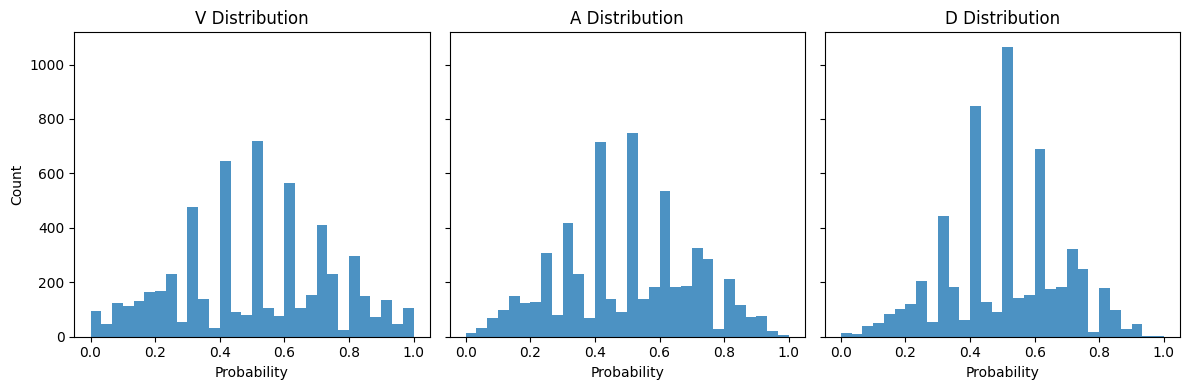

In [11]:
import matplotlib.pyplot as plt

prob_cols = [
    "Probability_A_greater_B_V",
    "Probability_A_greater_B_A",
    "Probability_A_greater_B_D",
]
labels = ["V", "A", "D"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, col, label in zip(axes, prob_cols, labels):
    eval_set_pairs[col].plot(kind="hist", bins=30, ax=ax, alpha=0.8)
    ax.set_title(f"{label} Distribution")
    ax.set_xlabel("Probability")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

# Build Model

### Key Updates to the Reward model framework to handle 3 dimensions and the probabilities (different from pairadigm):

- Triple Output Head: The model now outputs 3 scores (Valence, Arousal, Dominance) instead of 1
- Probability-Based Margins: Uses the probabilities directly as target margins, transformed via log-odds (log(p / (1−p))) to give a continuous signal that captures how much better A is compared to B
- Dataset Input Format: Now expects tuples of (text_A, text_B, prob_V, prob_A, prob_D) instead of winner/loser pairs
- Training Loss: Uses separate MSE losses for each dimension, summed together for joint training
- Scoring Methods:
    - score_text() now returns a dictionary with valence, arousal, dominance
    - score_batch() returns a dictionary with arrays for each dimension
- Evaluation: Tracks losses separately for each dimension

#### Why Log-Odds for Margins?
The probability range [0, 1] gets transformed to (-∞, +∞) via log-odds. This is more meaningful than raw probabilities because:

- 0.5 probability → 0 margin (A and B are equally good)
- 0.7 probability → ~0.85 margin (A is moderately better)
- 0.9 probability → ~2.2 margin (A is much better)

The stronger signal prevents the model from being overconfident early in training. 

## Setup

In [19]:
def make_tuples(data, margins = True):
    """Convert dataframe to list of tuples with all three probabilities."""
    if margins:
        return list(
            zip(
                data['Text_A'].tolist(),
                data['Text_B'].tolist(),
                data['Probability_A_greater_B_V'].tolist(),
                data['Probability_A_greater_B_A'].tolist(),
                data['Probability_A_greater_B_D'].tolist()
            )
        )
    return list(
        zip(
            data['Text_A'].tolist(),
            data['Text_B'].tolist(),
            data['A_better_indicator_V'].tolist(),
            data['A_better_indicator_A'].tolist(),
            data['A_better_indicator_D'].tolist()
        )
    )

make_tuples(train_set_pairs)[:2]  # Show first 2 examples

[('Looking beyond the iPhone',
  'Freaking hillarious and so true.',
  0.09999999999999998,
  0.19999999999999996,
  0.30000000000000004),
 ('This makes it an excellent and bountiful source of compost, and it was used for generations as a soil enricher.',
  'But haying had to happen regularly, says David: "There\'s so much oxygen in this soil, any added compost gets burned up in six weeks.',
  0.92,
  0.5,
  0.7)]

In [20]:
# Functions for evaluation of regression metrics on the splits to compare with PERT, etc.
def calculate_metrics(predictions: np.ndarray, targets: np.ndarray) -> Dict[str, float]:
    """Compute MAE, R2, and Pearson metrics (overall and per-dimension)."""
    mae = mean_absolute_error(targets, predictions)
    r2 = r2_score(targets, predictions)
    pearson = pearsonr(targets.flatten(), predictions.flatten())[0]

    mae_per_dim = [mean_absolute_error(targets[:, i], predictions[:, i]) for i in range(3)]
    r2_per_dim = [r2_score(targets[:, i], predictions[:, i]) for i in range(3)]
    pearson_per_dim = [pearsonr(targets[:, i], predictions[:, i])[0] for i in range(3)]

    return {
        'mae': mae,
        'r2': r2,
        'mae_valence': mae_per_dim[0],
        'mae_arousal': mae_per_dim[1],
        'mae_dominance': mae_per_dim[2],
        'r2_valence': r2_per_dim[0],
        'r2_arousal': r2_per_dim[1],
        'r2_dominance': r2_per_dim[2],
        'pearson': pearson,
        'pearson_valence': pearson_per_dim[0],
        'pearson_arousal': pearson_per_dim[1],
        'pearson_dominance': pearson_per_dim[2]
    }

def evaluate_regression_on_split(
    emobank_df: pd.DataFrame,
    split: str,
    reward_model: 'RewardModel',
    normalization_params: Optional[Dict[str, Dict[str, float]]] = None,
    batch_size: int = 32,
    scale_min: float = 1.0,
    scale_max: float = 5.0
) -> Dict[str, float]:
    """
    Score texts for a split and compute regression metrics vs gold V/A/D.
    
    Args:
        emobank_df: EmoBank dataframe
        split: 'train', 'dev', or 'test'
        reward_model: Trained reward model
        normalization_params: Pre-computed min/max params (if None, normalize within split)
        batch_size: Batch size for scoring
        scale_min: Minimum of target scale
        scale_max: Maximum of target scale
    """
    subset = emobank_df[emobank_df['split'] == split].copy()
    subset = subset.dropna(subset=['text', 'V', 'A', 'D'])
    if subset.empty:
        raise ValueError(f"No rows found for split '{split}' with V/A/D labels.")

    texts = subset['text'].tolist()
    targets = subset[['V', 'A', 'D']].values.astype(np.float32)
    
    # Get raw predictions
    preds_dict = reward_model.score_batch(texts, batch_size=batch_size)
    
    # Normalize predictions
    if normalization_params is not None:
        preds_dict = reward_model.normalize_scores_with_params(
            preds_dict, normalization_params, scale_min, scale_max
        )
    else:
        # Fallback: normalize within this split (not recommended for comparison)
        print(f"Warning: Normalizing {split} split independently. For fair comparison, provide normalization_params.")
        for dim in ['valence', 'arousal', 'dominance']:
            preds_dict[dim] = reward_model.normalize_scores(
                preds_dict[dim], scale_min, scale_max
            )
    
    predictions = np.vstack([
        preds_dict['valence'],
        preds_dict['arousal'],
        preds_dict['dominance']
    ]).T

    return calculate_metrics(predictions, targets)

In [ ]:
class RewardModel:
    """
    Unified class for training and using a reward model for text scoring.
    
    This class handles:
    - Model initialization and configuration
    - Dataset creation and management
    - Training loop with pairwise comparisons
    - Scoring individual texts or batches
    - Score normalization
    """
    
    def __init__(
        self,
        model_name: str = "answerdotai/ModernBERT-large",
        dropout: float = 0.1,
        max_length: int = 384,
        device: Optional[str] = None,
        Pairadigm: Optional['Pairadigm'] = None,
        seed: int = 42
    ):
        """
        Initialize the reward model trainer.
        
        Args:
            model_name: HuggingFace model identifier
            dropout: Dropout rate for reward head
            max_length: Maximum sequence length for tokenization
            device: Device to use ('cuda', 'cpu', or None for auto-detect)
        """
        # Set seeds at model initialization
        set_seeds(seed)

        self.model_name = model_name
        self.max_length = max_length
        if device:
            self.device = device
        elif torch.cuda.is_available():
            self.device = 'cuda'
        elif torch.backends.mps.is_available():
            self.device = 'mps'
        else:
            self.device = 'cpu'
        print(f"Model using device: {self.device}")
        
        # Initialize tokenizer
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        
        # Initialize model
        self.model = self._build_model(dropout)
        self.model.to(self.device)

        # If a Pairadigm instance is provided, link it
        self.pairadigm = Pairadigm
        
        # Training state
        self.optimizer = None
        self.scheduler = None
        self.scaler = GradScaler('cuda') # For mixed precision training
        self.training_history = []
        # self.loss_weights = {'V': 0.4, 'A': 0.3, 'D': 0.3}
    
    def _build_model(self, dropout: float) -> nn.Module:
        """Build the reward model architecture."""
        encoder = AutoModel.from_pretrained(self.model_name)
        hidden_size = encoder.config.hidden_size
        
        # Create complete model
        model = nn.Module()
        model.encoder = encoder
        # Output 3 scores: Valence, Arousal, Dominance
        model.reward_head = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.LayerNorm(hidden_size // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, hidden_size // 4),
            nn.LayerNorm(hidden_size // 4),
            nn.GELU(),
            nn.Dropout(dropout / 2),
            nn.Linear(hidden_size // 4, 3)
        )

        # Better initialization
        for module in model.reward_head.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight, gain=1)  # Smaller initial weights
                nn.init.zeros_(module.bias)
        
        # Add forward method
        def forward(input_ids, attention_mask):
            outputs = model.encoder(input_ids=input_ids, attention_mask=attention_mask)
            pooled_output = outputs.last_hidden_state[:, 0, :]
            rewards = model.reward_head(pooled_output)  # Shape: (batch_size, 3)
            return rewards
        
        model.forward = forward
        return model
    
    def prepare_data(
        self,
        pairs: Optional[List[Tuple[str, str, Union[int, float]]]] = None,
        batch_size: int = 16,
        shuffle: bool = True,
        decision_col: str = "decision",
        score_col: str = "Bradley_Terry_Score",
        margins: bool = True,
        test_size: float = 0.15,
        eval_size: float = 0.15,
        stratify: Optional[List] = None,
        random_state: Optional[int] = 42
    ) -> Dict[str, DataLoader]:
        """
        Prepare training, evaluation, and test data from pairwise comparisons.

        Args:
            pairs: Optional list of (text_winner, text_loser, margin) tuples. If None and a Pairadigm instance is linked, will use Pairadigm.
            batch_size: Batch size for training
            shuffle: Whether to shuffle the training data
            decision_col: Column name for decision in pairwise_df
            score_col: Column name for scores in scored_df
            margins: Whether to compute margins from scores
            test_size: Proportion of data for test set (default 0.15)
            eval_size: Proportion of data for eval set (default 0.15)
            stratify: Optional list of labels for stratified splitting
            random_state: Random seed for reproducibility

        Returns:
            Dictionary with 'train', 'eval', and 'test' DataLoaders
        """
        if pairs is None and self.pairadigm:
            pairs = self._prepare_pairadigm(
                decision_col=decision_col, 
                score_col=score_col, 
                margins=margins
            )
        elif pairs is None:
            raise ValueError("No pairs provided and no Pairadigm instance linked.")
        
        # Split data: first split into train+eval and test
        train_eval_pairs, test_pairs = train_test_split(
            pairs,
            test_size=test_size,
            stratify=stratify,
            random_state=random_state
        )
        
        # Then split train+eval into train and eval
        # Adjust eval_size to be relative to train+eval size
        adjusted_eval_size = eval_size / (1 - test_size)
        train_pairs, eval_pairs = train_test_split(
            train_eval_pairs,
            test_size=adjusted_eval_size,
            stratify=None,  # stratify only on first split
            random_state=random_state
        )
        
        print(f"Data split - Train: {len(train_pairs)}, Eval: {len(eval_pairs)}, Test: {len(test_pairs)}")
        
        # Create datasets and dataloaders
        train_dataset = self._PairwiseDataset(train_pairs, self.tokenizer, self.max_length)
        eval_dataset = self._PairwiseDataset(eval_pairs, self.tokenizer, self.max_length)
        test_dataset = self._PairwiseDataset(test_pairs, self.tokenizer, self.max_length)
        
        return {
            'train': DataLoader(train_dataset, batch_size=batch_size, shuffle=shuffle),
            'eval': DataLoader(eval_dataset, batch_size=batch_size, shuffle=False),
            'test': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
        }
    
    class _PairwiseDataset(Dataset):
        """Internal dataset class for pairwise comparisons with V/A/D probabilities."""
        
        def __init__(self, pairs, tokenizer, max_length):
            self.pairs = pairs
            self.tokenizer = tokenizer
            self.max_length = max_length
        
        def __len__(self):
            return len(self.pairs)
        
        def __getitem__(self, idx):
            # Expect tuples: (text_A, text_B, prob_V, prob_A, prob_D)
            text_A, text_B, prob_V, prob_A, prob_D = self.pairs[idx]
            
            encoding_A = self.tokenizer(
                text_A,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            encoding_B = self.tokenizer(
                text_B,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            return {
                'input_ids_A': encoding_A['input_ids'].squeeze(0),
                'attention_mask_A': encoding_A['attention_mask'].squeeze(0),
                'input_ids_B': encoding_B['input_ids'].squeeze(0),
                'attention_mask_B': encoding_B['attention_mask'].squeeze(0),
                'prob_V': torch.tensor(prob_V, dtype=torch.float),
                'prob_A': torch.tensor(prob_A, dtype=torch.float),
                'prob_D': torch.tensor(prob_D, dtype=torch.float)
            }
    
    def train(
        self,
        train_loader: DataLoader,
        eval_loader: DataLoader,
        epochs: int = 5,
        learning_rate: float = 2e-5,
        weight_decay: float = 0.01,
        warmup_steps: int = 100,
        log_interval: int = 50,
        early_stopping_patience: int = 3,
        accumulation_steps: int = 1
    ):
        """
        Train the reward model on pairwise comparison data with optional early stopping and gradient accumulation.

        Args:
            train_loader: DataLoader with training pairs (mini-batch size)
            eval_loader: DataLoader for evaluation (required for early stopping)
            epochs: Number of training epochs
            learning_rate: Learning rate for optimizer
            warmup_steps: Number of warmup steps for scheduler
            log_interval: Log metrics every N steps
            early_stopping_patience: Number of epochs with no improvement on eval loss before stopping early.
                                     Set to None or 0 to disable early stopping.
            accumulation_steps: Number of gradient accumulation steps (effective_batch_size = mini_batch_size * accumulation_steps)
        Returns:
            The model (self.model) restored to the best-performing weights observed on eval data.
        """
        self.model.train()
        
        # Setup optimizer and scheduler
        self.optimizer = AdamW(
            self.model.parameters(), 
            lr=learning_rate, 
            weight_decay=weight_decay
        )
        total_steps = len(train_loader) * epochs
        self.scheduler = get_linear_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=total_steps
        )

        # Early stopping bookkeeping
        best_state = None
        best_eval_loss = float('inf')
        epochs_without_improve = 0
        use_early_stopping = bool(early_stopping_patience and eval_loader is not None and early_stopping_patience > 0)
        
        for epoch in range(epochs):
            # # Freeze encoder on first epoch, gradually unfreeze after
            # if epoch == 0:
            #     for param in self.model.encoder.parameters():
            #         param.requires_grad = False
            # elif epoch <= 2:  # Gradual unfreezing
            #     for i, layer in enumerate(self.model.encoder.encoder.layer):
            #         if i >= len(self.model.encoder.encoder.layer) - 4:  # Unfreeze last 4 layers
            #             for param in layer.parameters():
            #                 param.requires_grad = True
            # else:
            #     for param in self.model.encoder.parameters():
            #         param.requires_grad = True
            
            epoch_loss = 0
            progress_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")
            self.optimizer.zero_grad()  # Zero gradients at start of epoch
            
            for step, batch in enumerate(progress_bar):
                # Perform forward/backward pass, accumulate gradients
                loss = self._training_step(batch, accumulation_steps)
                epoch_loss += loss
                
                # Update weights after accumulation_steps
                if (step + 1) % accumulation_steps == 0:
                    self.scaler.unscale_(self.optimizer)
                    grad_norm = torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                    self.scheduler.step()
                    self.optimizer.zero_grad()
                
                if (step + 1) % log_interval == 0:
                    avg_loss = epoch_loss / (step + 1)
                    progress_bar.set_postfix({'loss': f'{avg_loss:.4f}', 'grad_norm': f'{grad_norm:.4f}'})
            
            avg_epoch_loss = epoch_loss / len(train_loader)
            epoch_metrics = {'epoch': epoch + 1, 'train_loss': avg_epoch_loss}
            
            print(f"Epoch {epoch + 1} - Train Loss: {avg_epoch_loss:.4f}")
            
            # Evaluation
            if eval_loader:
                eval_metrics = self.evaluate(eval_loader)
                epoch_metrics.update(eval_metrics)
                print(f"Epoch {epoch + 1} - Eval Loss: {eval_metrics['eval_loss']:.4f} | Accuracy: {eval_metrics['eval_accuracy']:.2%}")
                print(f"  Loss - V: {eval_metrics['eval_loss_V']:.4f} | A: {eval_metrics['eval_loss_A']:.4f} | D: {eval_metrics['eval_loss_D']:.4f}")
                print(f"  Acc  - V: {eval_metrics['eval_accuracy_V']:.2%} | A: {eval_metrics['eval_accuracy_A']:.2%} | D: {eval_metrics['eval_accuracy_D']:.2%}")
                
                # Check for improvement on eval_loss and save best model
                current_eval_loss = eval_metrics.get('eval_loss', float('inf'))
                if current_eval_loss < best_eval_loss:
                    best_eval_loss = current_eval_loss
                    # store a CPU copy of the state dict
                    best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
                    epochs_without_improve = 0
                    print(f"  New best model found (eval_loss improved to {best_eval_loss:.4f}).")
                else:
                    epochs_without_improve += 1
                    print(f"  No improvement for {epochs_without_improve} epoch(s).")
            
            else:
                # If no eval_loader provided, we can't do early stopping / track best by eval
                best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}
            
            self.training_history.append(epoch_metrics)

            # Early stopping check
            if use_early_stopping and epochs_without_improve >= early_stopping_patience:
                print(f"Early stopping triggered after {epoch + 1} epochs (no improvement in eval loss for {early_stopping_patience} epochs).")
                break
        
        # Restore best model weights if we tracked them
        if best_state is not None:
            # move tensors back to device as needed when loading
            device_state = {k: v.to(self.device) for k, v in best_state.items()}
            self.model.load_state_dict(device_state)
            print("Best model weights restored based on eval data.")
        
        return self.model
    
    def _training_step(self, batch, accumulation_steps: int = 1) -> float:
        """Single training step with V/A/D dimensions using soft cross-entropy pairwise loss.
        
        Args:
            batch: Dictionary containing input_ids, attention_masks, and probabilities
            accumulation_steps: Number of steps to accumulate gradients over
            
        Returns:
            Loss value for this step
        """
        batch = {key: value.to(self.device) for key, value in batch.items()}
        
        with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
            rewards_A = self.model(
                batch['input_ids_A'],
                batch['attention_mask_A']
            )
            rewards_B = self.model(
                batch['input_ids_B'],
                batch['attention_mask_B']
            )
            
            # Soft cross-entropy loss with informativeness weighting
            # loss = -[p * log(σ(r_A - r_B)) + (1-p) * log(σ(r_B - r_A))]
            # weight = |2 * (p - 0.5)|  → 0 at p=0.5 (tie), 1 at p=0 or p=1
            eps = 1e-7  # For numerical stability
            
            # Valence
            prob_V = batch['prob_V']
            logit_V = rewards_A[:, 0] - rewards_B[:, 0]
            per_sample_loss_V = -(prob_V * torch.log(torch.sigmoid(logit_V) + eps) + 
                       (1 - prob_V) * torch.log(torch.sigmoid(-logit_V) + eps))
            weight_V = (2 * (prob_V - 0.5)).abs()
            loss_V = (per_sample_loss_V * weight_V).mean()
            
            # Arousal
            prob_A = batch['prob_A']
            logit_A = rewards_A[:, 1] - rewards_B[:, 1]
            per_sample_loss_A = -(prob_A * torch.log(torch.sigmoid(logit_A) + eps) + 
                       (1 - prob_A) * torch.log(torch.sigmoid(-logit_A) + eps))
            weight_A = (2 * (prob_A - 0.5)).abs()
            loss_A = (per_sample_loss_A * weight_A).mean()
            
            # Dominance
            prob_D = batch['prob_D']
            logit_D = rewards_A[:, 2] - rewards_B[:, 2]
            per_sample_loss_D = -(prob_D * torch.log(torch.sigmoid(logit_D) + eps) + 
                       (1 - prob_D) * torch.log(torch.sigmoid(-logit_D) + eps))
            weight_D = (2 * (prob_D - 0.5)).abs()
            loss_D = (per_sample_loss_D * weight_D).mean()
            
            total_loss = (loss_V + loss_A + loss_D) / accumulation_steps
        
        self.scaler.scale(total_loss).backward()
        return total_loss.item() * accumulation_steps
    
    def _compute_pairwise_accuracy(self, batch) -> Dict[str, float]:
        """Compute pairwise accuracy for V/A/D dimensions."""
        batch = {key: value.to(self.device) for key, value in batch.items()}
        
        with torch.no_grad():
            rewards_A = self.model(batch['input_ids_A'], batch['attention_mask_A'])
            rewards_B = self.model(batch['input_ids_B'], batch['attention_mask_B'])
        
        # For each dimension, check if model ranking matches indicator
        # indicator=1 means A should be better (reward_A > reward_B)
        # indicator=0 means B should be better (reward_B > reward_A)
        
        correct_V = ((batch['prob_V'] > 0.5) & (rewards_A[:, 0] > rewards_B[:, 0])) | \
                    ((batch['prob_V'] <= 0.5) & (rewards_B[:, 0] > rewards_A[:, 0]))
        
        correct_A = ((batch['prob_A'] > 0.5) & (rewards_A[:, 1] > rewards_B[:, 1])) | \
                    ((batch['prob_A'] <= 0.5) & (rewards_B[:, 1] > rewards_A[:, 1]))
        
        correct_D = ((batch['prob_D'] > 0.5) & (rewards_A[:, 2] > rewards_B[:, 2])) | \
                    ((batch['prob_D'] <= 0.5) & (rewards_B[:, 2] > rewards_A[:, 2]))
        
        return {
            'accuracy_V': correct_V.float().mean().item(),
            'accuracy_A': correct_A.float().mean().item(),
            'accuracy_D': correct_D.float().mean().item(),
            'accuracy_overall': (correct_V.float() + correct_A.float() + correct_D.float()).mean().item() / 3
        }
    
    def evaluate(self, eval_loader: DataLoader) -> Dict[str, float]:
        """Evaluate the model on a validation set using soft cross-entropy loss and accuracy."""
        self.model.eval()
        total_loss = 0
        losses_by_dim = {'V': 0, 'A': 0, 'D': 0}
        
        total_correct_V = 0
        total_correct_A = 0
        total_correct_D = 0
        total_samples = 0
        
        eps = 1e-7
        
        with torch.no_grad():
            for batch in eval_loader:
                batch = {key: value.to(self.device) for key, value in batch.items()}
                
                rewards_A = self.model(
                    batch['input_ids_A'],
                    batch['attention_mask_A']
                )
                rewards_B = self.model(
                    batch['input_ids_B'],
                    batch['attention_mask_B']
                )
                
                # Soft cross-entropy loss with informativeness weighting
                prob_V = batch['prob_V']
                logit_V = rewards_A[:, 0] - rewards_B[:, 0]
                per_sample_loss_V = -(prob_V * torch.log(torch.sigmoid(logit_V) + eps) + 
                          (1 - prob_V) * torch.log(torch.sigmoid(-logit_V) + eps))
                weight_V = (2 * (prob_V - 0.5)).abs()
                loss_V = (per_sample_loss_V * weight_V).mean()
                
                prob_A = batch['prob_A']
                logit_A = rewards_A[:, 1] - rewards_B[:, 1]
                per_sample_loss_A = -(prob_A * torch.log(torch.sigmoid(logit_A) + eps) + 
                          (1 - prob_A) * torch.log(torch.sigmoid(-logit_A) + eps))
                weight_A = (2 * (prob_A - 0.5)).abs()
                loss_A = (per_sample_loss_A * weight_A).mean()
                
                prob_D = batch['prob_D']
                logit_D = rewards_A[:, 2] - rewards_B[:, 2]
                per_sample_loss_D = -(prob_D * torch.log(torch.sigmoid(logit_D) + eps) + 
                          (1 - prob_D) * torch.log(torch.sigmoid(-logit_D) + eps))
                weight_D = (2 * (prob_D - 0.5)).abs()
                loss_D = (per_sample_loss_D * weight_D).mean()
                
                batch_loss = loss_V + loss_A + loss_D
                total_loss += batch_loss.item()
                losses_by_dim['V'] += loss_V.item()
                losses_by_dim['A'] += loss_A.item()
                losses_by_dim['D'] += loss_D.item()
                
                # Accuracy: does the model agree with the majority preference?
                correct_V = ((prob_V > 0.5) & (rewards_A[:, 0] > rewards_B[:, 0])) | \
                           ((prob_V < 0.5) & (rewards_B[:, 0] > rewards_A[:, 0]))
                correct_A = ((prob_A > 0.5) & (rewards_A[:, 1] > rewards_B[:, 1])) | \
                           ((prob_A < 0.5) & (rewards_B[:, 1] > rewards_A[:, 1]))
                correct_D = ((prob_D > 0.5) & (rewards_A[:, 2] > rewards_B[:, 2])) | \
                           ((prob_D < 0.5) & (rewards_B[:, 2] > rewards_A[:, 2]))
                
                # Exclude ties (prob == 0.5) from accuracy computation
                non_tie_V = (prob_V != 0.5)
                non_tie_A = (prob_A != 0.5)
                non_tie_D = (prob_D != 0.5)
                
                total_correct_V += correct_V[non_tie_V].sum().item()
                total_correct_A += correct_A[non_tie_A].sum().item()
                total_correct_D += correct_D[non_tie_D].sum().item()
                total_samples += len(prob_V)  # For loss averaging
        
        self.model.train()
        
        accuracy_V = total_correct_V / max(total_samples, 1)
        accuracy_A = total_correct_A / max(total_samples, 1)
        accuracy_D = total_correct_D / max(total_samples, 1)
        accuracy_overall = (accuracy_V + accuracy_A + accuracy_D) / 3
        
        return {
            'eval_loss': total_loss / len(eval_loader),
            'eval_loss_V': losses_by_dim['V'] / len(eval_loader),
            'eval_loss_A': losses_by_dim['A'] / len(eval_loader),
            'eval_loss_D': losses_by_dim['D'] / len(eval_loader),
            'eval_accuracy': accuracy_overall,
            'eval_accuracy_V': accuracy_V,
            'eval_accuracy_A': accuracy_A,
            'eval_accuracy_D': accuracy_D
        }
    
    def score_text(self, text: str) -> Dict[str, float]:
        """
        Score a single text item across all three dimensions (V, A, D).
        
        Args:
            text: Text to score
            
        Returns:
            Dictionary with 'valence', 'arousal', 'dominance' scores
        """
        self.model.eval()
        
        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        
        with torch.no_grad():
            rewards = self.model(
                encoding['input_ids'].to(self.device),
                encoding['attention_mask'].to(self.device)
            )
        
        return {
            'valence': rewards[0, 0].item(),
            'arousal': rewards[0, 1].item(),
            'dominance': rewards[0, 2].item()
        }
    
    def score_batch(self, texts: List[str], batch_size: int = 32) -> Dict[str, np.ndarray]:
        """
        Score multiple texts efficiently across all three dimensions.
        
        Args:
            texts: List of texts to score
            batch_size: Batch size for processing
            
        Returns:
            Dictionary with 'valence', 'arousal', 'dominance' arrays
        """
        self.model.eval()
        scores_V = []
        scores_A = []
        scores_D = []
        
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i + batch_size]
            encodings = self.tokenizer(
                batch_texts,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            with torch.no_grad():
                rewards = self.model(
                    encodings['input_ids'].to(self.device),
                    encodings['attention_mask'].to(self.device)
                )
            
            scores_V.extend(rewards[:, 0].cpu().numpy())
            scores_A.extend(rewards[:, 1].cpu().numpy())
            scores_D.extend(rewards[:, 2].cpu().numpy())
        
        return {
            'valence': np.array(scores_V),
            'arousal': np.array(scores_A),
            'dominance': np.array(scores_D)
        }
    
    def fit_normalization_params(
        self,
        texts: List[str],
        batch_size: int = 32
    ) -> Dict[str, Dict[str, float]]:
        """
        Fit normalization parameters using percentiles for robustness."""
        scores = self.score_batch(texts, batch_size=batch_size)
        
        params = {}
        for dim in ['valence', 'arousal', 'dominance']:
            dim_scores = scores[dim]
            # Use 1st/99th percentiles instead of raw min/max
            p_low = float(np.percentile(dim_scores, 1))
            p_high = float(np.percentile(dim_scores, 99))
            params[dim] = {'min': p_low, 'max': p_high}
        
        return params
    
    def normalize_scores_with_params(
        self,
        scores: Dict[str, np.ndarray],
        params: Dict[str, Dict[str, float]],
        scale_min: float = 1.0,
        scale_max: float = 5.0,
        clip: bool = True
    ) -> Dict[str, np.ndarray]:
        """
        Normalize scores using pre-computed parameters.
        
        Args:
            scores: Dictionary with 'valence', 'arousal', 'dominance' arrays
            params: Min/max parameters for each dimension from fit_normalization_params
            scale_min: Minimum value of output scale (EmoBank uses 1)
            scale_max: Maximum value of output scale (EmoBank uses 5)
            clip: Whether to clip values to [scale_min, scale_max]
            
        Returns:
            Dictionary with normalized scores
        """
        normalized = {}
        
        for dim in ['valence', 'arousal', 'dominance']:
            dim_min = params[dim]['min']
            dim_max = params[dim]['max']
            
            if dim_max == dim_min:
                # If no variance, use midpoint
                normalized[dim] = np.full_like(scores[dim], (scale_min + scale_max) / 2)
            else:
                # Linear scaling
                norm = (scores[dim] - dim_min) / (dim_max - dim_min)
                norm = norm * (scale_max - scale_min) + scale_min
                
                if clip:
                    norm = np.clip(norm, scale_min, scale_max)
                
                normalized[dim] = norm
        
        return normalized
    
    def normalize_scores(
        self,
        scores: np.ndarray,
        scale_min: float = 0.0,
        scale_max: float = 1.0
    ) -> np.ndarray:
        """
        Normalize raw reward scores to a desired scale.
        This normalizes within the provided scores (relative scaling).
        For consistent scaling across splits, use normalize_scores_with_params instead.
        
        Args:
            scores: Raw scores to normalize
            scale_min: Minimum value of output scale
            scale_max: Maximum value of output scale
            
        Returns:
            Normalized scores
        """
        score_min = scores.min()
        score_max = scores.max()
        
        if score_max == score_min:
            return np.full_like(scores, (scale_min + scale_max) / 2)
        
        normalized = (scores - score_min) / (score_max - score_min)
        normalized = normalized * (scale_max - scale_min) + scale_min
        
        return normalized
    
    def test_model(self, test_loader: DataLoader) -> Dict[str, float]:
        """Evaluate the model on the test set using soft cross-entropy loss and accuracy."""
        print("\n" + "="*60)
        print("Running Test Evaluation (V, A, D)")
        print("="*60)
        
        self.model.eval()
        total_loss = 0
        losses_by_dim = {'V': 0, 'A': 0, 'D': 0}
        
        total_correct_V = 0
        total_correct_A = 0
        total_correct_D = 0
        total_samples = 0
        
        eps = 1e-7
        
        with torch.no_grad():
            for batch in tqdm(test_loader, desc="Testing"):
                batch = {key: value.to(self.device) for key, value in batch.items()}
                
                rewards_A = self.model(
                    batch['input_ids_A'],
                    batch['attention_mask_A']
                )
                rewards_B = self.model(
                    batch['input_ids_B'],
                    batch['attention_mask_B']
                )
                
                # Soft cross-entropy loss with informativeness weighting
                prob_V = batch['prob_V']
                logit_V = rewards_A[:, 0] - rewards_B[:, 0]
                per_sample_loss_V = -(prob_V * torch.log(torch.sigmoid(logit_V) + eps) + 
                          (1 - prob_V) * torch.log(torch.sigmoid(-logit_V) + eps))
                weight_V = (2 * (prob_V - 0.5)).abs()
                loss_V = (per_sample_loss_V * weight_V).mean()
                
                prob_A = batch['prob_A']
                logit_A = rewards_A[:, 1] - rewards_B[:, 1]
                per_sample_loss_A = -(prob_A * torch.log(torch.sigmoid(logit_A) + eps) + 
                          (1 - prob_A) * torch.log(torch.sigmoid(-logit_A) + eps))
                weight_A = (2 * (prob_A - 0.5)).abs()
                loss_A = (per_sample_loss_A * weight_A).mean()
                
                prob_D = batch['prob_D']
                logit_D = rewards_A[:, 2] - rewards_B[:, 2]
                per_sample_loss_D = -(prob_D * torch.log(torch.sigmoid(logit_D) + eps) + 
                          (1 - prob_D) * torch.log(torch.sigmoid(-logit_D) + eps))
                weight_D = (2 * (prob_D - 0.5)).abs()
                loss_D = (per_sample_loss_D * weight_D).mean()
                
                batch_loss = loss_V + loss_A + loss_D
                total_loss += batch_loss.item()
                losses_by_dim['V'] += loss_V.item()
                losses_by_dim['A'] += loss_A.item()
                losses_by_dim['D'] += loss_D.item()
                
                # Consistent accuracy: use > 0.5 / < 0.5 (same as evaluate)
                correct_V = ((prob_V > 0.5) & (rewards_A[:, 0] > rewards_B[:, 0])) | \
                           ((prob_V < 0.5) & (rewards_B[:, 0] > rewards_A[:, 0]))
                correct_A = ((prob_A > 0.5) & (rewards_A[:, 1] > rewards_B[:, 1])) | \
                           ((prob_A < 0.5) & (rewards_B[:, 1] > rewards_A[:, 1]))
                correct_D = ((prob_D > 0.5) & (rewards_A[:, 2] > rewards_B[:, 2])) | \
                           ((prob_D < 0.5) & (rewards_B[:, 2] > rewards_A[:, 2]))
                
                non_tie_V = (prob_V != 0.5)
                non_tie_A = (prob_A != 0.5)
                non_tie_D = (prob_D != 0.5)
                
                total_correct_V += correct_V[non_tie_V].sum().item()
                total_correct_A += correct_A[non_tie_A].sum().item()
                total_correct_D += correct_D[non_tie_D].sum().item()
                total_samples += len(prob_V)
        
        test_loss = total_loss / len(test_loader)
        test_loss_V = losses_by_dim['V'] / len(test_loader)
        test_loss_A = losses_by_dim['A'] / len(test_loader)
        test_loss_D = losses_by_dim['D'] / len(test_loader)
        
        accuracy_V = total_correct_V / max(total_samples, 1)
        accuracy_A = total_correct_A / max(total_samples, 1)
        accuracy_D = total_correct_D / max(total_samples, 1)
        accuracy_overall = (accuracy_V + accuracy_A + accuracy_D) / 3
        
        print(f"\nTest Results:")
        print(f"  Total Loss: {test_loss:.4f} | Accuracy: {accuracy_overall:.2%}")
        print(f"  Valence   - Loss: {test_loss_V:.4f} | Acc: {accuracy_V:.2%}")
        print(f"  Arousal   - Loss: {test_loss_A:.4f} | Acc: {accuracy_A:.2%}")
        print(f"  Dominance - Loss: {test_loss_D:.4f} | Acc: {accuracy_D:.2%}")
        print("\n" + "="*60 + "\n")
        
        results = {
            'test_loss': test_loss,
            'test_loss_V': test_loss_V,
            'test_loss_A': test_loss_A,
            'test_loss_D': test_loss_D,
            'test_accuracy': accuracy_overall,
            'test_accuracy_V': accuracy_V,
            'test_accuracy_A': accuracy_A,
            'test_accuracy_D': accuracy_D
        }
        
        return results
    
    def save(self, path: str):
        """Save model and training state."""
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict() if self.optimizer else None,
            'scheduler_state_dict': self.scheduler.state_dict() if self.scheduler else None,
            'training_history': self.training_history,
            'config': {
                'model_name': self.model_name,
                'max_length': self.max_length
            }
        }, path)
        print(f"Model saved to {path}")
    
    def load(self, path: str):
        """Load model and training state."""
        checkpoint = torch.load(path, map_location=self.device)
        self.model.load_state_dict(checkpoint['model_state_dict'])
        
        if checkpoint['optimizer_state_dict'] and self.optimizer:
            self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        
        if checkpoint['scheduler_state_dict'] and self.scheduler:
            self.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        
        self.training_history = checkpoint.get('training_history', [])
        print(f"Model loaded from {path}")

    def push_to_hub(self, repo_id: str, private: bool = True):
        """
        Push the trained model to HuggingFace Hub.
        
        Args:
            repo_id: Repository ID in format "username/repo-name"
            private: Whether to make the repository private (default True)
        """
        from huggingface_hub import create_repo, upload_folder
        import os
        
        # Create a temporary directory for the model files
        temp_dir = f"./temp_model_{repo_id.split('/')[-1]}"
        os.makedirs(temp_dir, exist_ok=True)
        
        try:
            # Save encoder and reward head
            self.model.encoder.save_pretrained(os.path.join(temp_dir, "encoder"))
            self.tokenizer.save_pretrained(temp_dir)
            torch.save(self.model.reward_head.state_dict(), os.path.join(temp_dir, "reward_head.pt"))
            
            # Save metadata
            metadata = {
                'model_name': self.model_name,
                'max_length': self.max_length,
                'training_history': self.training_history
            }
            with open(os.path.join(temp_dir, "training_metadata.json"), 'w') as f:
                json.dump(metadata, f, indent=2)
            
            # Create and upload to Hub
            create_repo(repo_id, private=private, exist_ok=True)
            upload_folder(repo_name=repo_id, folder_path=temp_dir, repo_type="model")
            
            print(f"Model successfully pushed to HuggingFace Hub: https://huggingface.co/{repo_id}")
        
        finally:
            # Clean up temporary directory
            import shutil
            if os.path.exists(temp_dir):
                shutil.rmtree(temp_dir)


## Run

In [ ]:
# Train the reward model using the prepared pairwise data
learning_rate = 1e-5
weight_decay = 0.01
epochs = 10
patience = 5
dropout = 0.1
batch_size = 16  # Mini-batch size that fits in GPU memory
accumulation_steps = 4  # Gradient accumulation steps (effective batch size = 16 * 4 = 64)
max_length = 256
seed_num = 42

effective_batch_size = batch_size * accumulation_steps
print(f"Training parameters - Epochs: {epochs}, LR: {learning_rate}, Weight Decay: {weight_decay}, Patience: {patience}, Dropout: {dropout}")
print(f"Batch Configuration - Mini-batch Size: {batch_size}, Accumulation Steps: {accumulation_steps}, Effective Batch Size: {effective_batch_size}, Seed: {seed_num}")

In [ ]:
print("Initializing Reward Model...")
reward_model = RewardModel(
    model_name="roberta-large",
    dropout=dropout,
    max_length=max_length,
    device=device 
)
print("Reward Model initialized.")

print("Preparing data loaders...")
num_workers = 4 if torch.cuda.is_available() else 0

# Convert to tuples format (use probabilities as soft labels)
train_tuples = make_tuples(train_set_pairs, margins=True)
eval_tuples = make_tuples(eval_set_pairs, margins=True)
test_tuples = make_tuples(test_set_pairs, margins=True)

# Create datasets manually
train_dataset = reward_model._PairwiseDataset(train_tuples, reward_model.tokenizer, reward_model.max_length)
eval_dataset = reward_model._PairwiseDataset(eval_tuples, reward_model.tokenizer, reward_model.max_length)
test_dataset = reward_model._PairwiseDataset(test_tuples, reward_model.tokenizer, reward_model.max_length)

# Calculate warmup steps based on effective batches (after accumulation)
warmup_steps = int(0.02 * (len(train_dataset) / (batch_size * accumulation_steps)) * epochs)
log_interval = 50

# Create dataloaders with fixed generator for reproducibility
generator = torch.Generator()
generator.manual_seed(seed_num)

data_loaders = {
    'train': DataLoader(train_dataset, batch_size=batch_size, shuffle=True, 
                       generator=generator, worker_init_fn=lambda _: set_seeds(seed_num)),
    'eval': DataLoader(eval_dataset, batch_size=batch_size, shuffle=False),
    'test': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
}

print("Data loaders ready.")
print(f"Train pairs: {len(train_tuples)}")
print(f"Eval pairs: {len(eval_tuples)}")
print(f"Test pairs: {len(test_tuples)}")

Model using device: cuda:0


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Train pairs: 68586
Eval pairs: 5785
Test pairs: 5786


In [ ]:
# Save training arguments for reproducibility
date = datetime.now().strftime("%Y%m%d")

print("Saving training arguments...")
os.makedirs("../Results/trained models", exist_ok=True)
training_args = {
    'model_name': reward_model.model_name,
    'num_epochs': epochs,
    'batch_size': batch_size,
    'accumulation_steps': accumulation_steps,
    'effective_batch_size': effective_batch_size,
    'learning_rate': learning_rate,
    'device': device_name,
    'weight_decay': weight_decay,
    'warmup_steps': warmup_steps,
    'dropout': dropout,
    'max_length': max_length,
    'seed': seed_num,
    'patience': patience,
    'log_interval': log_interval
}
with open(f"../Results/trained models/emobank_reward_model_training_args_{date}.json", "w") as f:
    json.dump(training_args, f, indent=4)

In [ ]:
print("Starting training...")
try:
    emobank_reward = reward_model.train(
        train_loader=data_loaders['train'],
        eval_loader=data_loaders['eval'],
        epochs=epochs,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        warmup_steps=warmup_steps,
        log_interval=log_interval,
        early_stopping_patience=patience,
        accumulation_steps=accumulation_steps
    )
    
    # Save immediately after training
    reward_model.save(f"../Results/trained models/emobank_reward_model_{date}.pth")
    
except Exception as e:
    print(f"Training failed: {e}")
    # Save checkpoint even if failed
    reward_model.save(f"../Results/trained models/emobank_reward_model_checkpoint_{date}.pth")
    raise

print("Training completed.")

# Save Results

In [ ]:
# After loading the best model, evaluate on test set
test_results = reward_model.test_model(data_loaders['test'])

In [ ]:
# Fit normalization parameters on training data
print("\nFitting normalization parameters on training data...")
train_texts = emobank[emobank['split'] == 'train']['text'].tolist()
normalization_params = reward_model.fit_normalization_params(train_texts, batch_size=32)
print(f"Normalization parameters:")
for dim in ['valence', 'arousal', 'dominance']:
    print(f"  {dim.capitalize()}: min={normalization_params[dim]['min']:.4f}, max={normalization_params[dim]['max']:.4f}")

# Save normalization parameters
with open(f"../Results/trained models/emobank_reward_model_norm_params_{date}.json", "w") as f:
    json.dump(normalization_params, f, indent=4)
print(f"Normalization parameters saved.")

# Compute regression-style metrics for comparison against gold V/A/D
print("\nComputing regression metrics vs gold V/A/D...")
regression_metrics_test = evaluate_regression_on_split(
    emobank_df=emobank,
    split='test',
    reward_model=reward_model,
    normalization_params=normalization_params,
    batch_size=32,
    scale_min=1.0,
    scale_max=5.0
)
regression_metrics_dev = evaluate_regression_on_split(
    emobank_df=emobank,
    split='dev',
    reward_model=reward_model,
    normalization_params=normalization_params,
    batch_size=32,
    scale_min=1.0,
    scale_max=5.0
)
print(f"Regression Metrics (dev): {regression_metrics_dev}")
print(f"Regression Metrics (test): {regression_metrics_test}")

In [ ]:
# Save metrics
metrics_payload = {
    'dev': {k: float(v) for k, v in regression_metrics_dev.items()},
    'test': {k: float(v) for k, v in regression_metrics_test.items()}
}
with open(f"../Results/trained models/emobank_reward_model_regression_metrics_{date}.json", "w") as f:
    json.dump(metrics_payload, f, indent=4)

In [ ]:
# Save test results
test_results_df = pd.DataFrame([test_results])
test_results_df.to_csv(f"../Results/trained models/emobank_reward_model_test_results_{date}.csv", index=False)

In [ ]:
# Save the trained model
reward_model.save(f"../Results/trained models/emobank_reward_model_{date}.pth")

In [ ]:
# Save training history to CSV
history_df = pd.DataFrame(reward_model.training_history)
history_df.to_csv(f"../Results/trained models/emobank_reward_model_training_history_{date}.csv", index=False)

In [ ]:
# Clean up memory after testing
import gc

print("Cleaning up memory...")
del emobank_reward
del data_loaders
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Available: {torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0)}")
print("Memory cleanup complete.")

In [18]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Available: {torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0)}")
print("Memory cleanup complete.")

GPU memory freed. Available: 20991901696
Memory cleanup complete.


# Load Trained Model

In [ ]:
# Load Model 
trained_model_path = "../Results/trained models/emobank_reward_model_20260216.pth"
reward_model = RewardModel(
    model_name="roberta-large",
    dropout=0.1,
    max_length=256,
    device=device 
)
reward_model.load(trained_model_path)

In [ ]:
reward_model.training_history

In [ ]:
import matplotlib.pyplot as plt

# Convert to DataFrame
history_df = pd.DataFrame(reward_model.training_history)
if history_df.empty:
    print("No training history to plot.")
else:
    # Ensure an epoch column exists
    if 'epoch' not in history_df.columns:
        history_df = history_df.reset_index().rename(columns={'index': 'epoch'})
        history_df['epoch'] = history_df['epoch'] + 1

    plt.figure(figsize=(9,5))
    if 'train_loss' in history_df.columns:
        plt.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='train_loss')
    if 'eval_loss' in history_df.columns:
        plt.plot(history_df['epoch'], history_df['eval_loss'], marker='o', label='eval_loss')
    for col, label in [('eval_loss_V', 'Valence'), ('eval_loss_A', 'Arousal'), ('eval_loss_D', 'Dominance')]:
        if col in history_df.columns:
            plt.plot(history_df['epoch'], history_df[col], marker='x', label=label)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Reward Model Training History')
    plt.legend()
    plt.grid(True)
    plt.show()